In [4]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
import os
import sys
import torch

sys.path.insert(0, os.path.abspath("../python_scripts"))

from data import ASSETS, MODEL_PATH, list_meshes, NUM_CLASSES, CLASS_NAMES
from features import build_datasets
from model import MiniDiffusionNet
from data import load_mesh
from train import train, set_seed
from evaluate import confusion_matrix, iou_from_confusion
import plotting

set_seed(0)
device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
ASSETS.mkdir(exist_ok=True)
print("device:", device)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
device: cuda:0


## Data
One example mesh from each source dataset, aligned upright.

381 train meshes, 18 test meshes


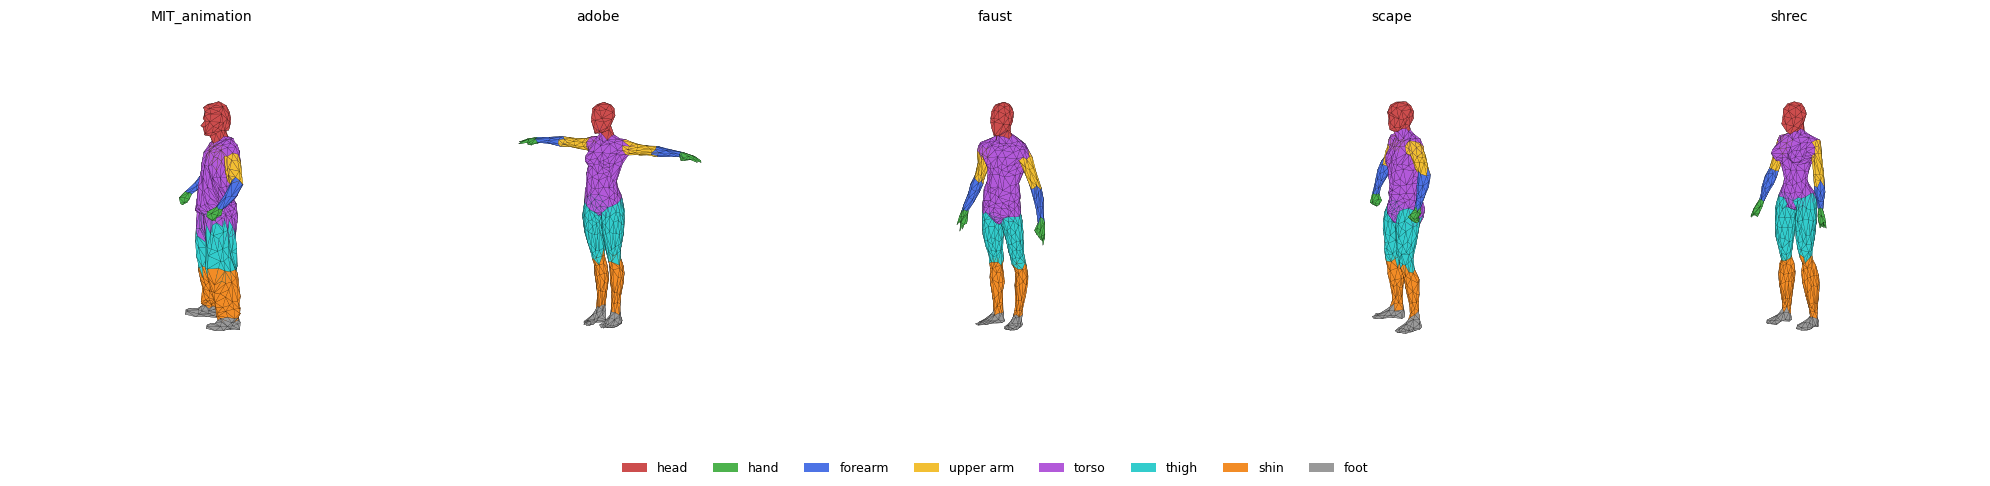

In [5]:
train_paths, test_paths = list_meshes()
print(f"{len(train_paths)} train meshes, {len(test_paths)} test meshes")
plotting.plot_samples(train_paths, test_paths, ncols=5)

## Preprocessing
Laplacian eigenbasis (k=128) and heat kernel signature for every mesh.

In [6]:
train_data, test_data, train_dev, test_dev, t = build_datasets(train_paths, test_paths, device)

### Laplacian eigenvectors
Low frequencies vary smoothly over the whole body; higher ones over smaller parts.

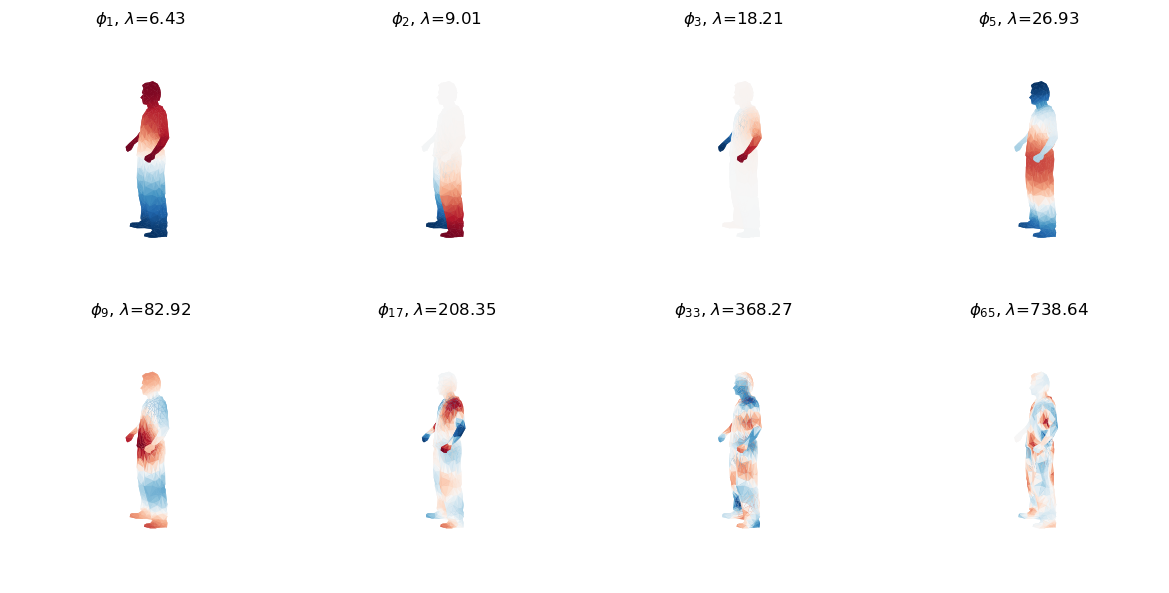

In [7]:
d = train_data[0]
plotting.plot_eigenvectors(d["V"].numpy(), d["Fc"].numpy(), d["evecs"], d["evals"],
                           ks=[0, 1, 2, 4, 8, 16, 32, 64], filename=ASSETS / "laplace.png")

### Heat kernel signature
Small t describes local curvature, large t describes where on the body a point is.

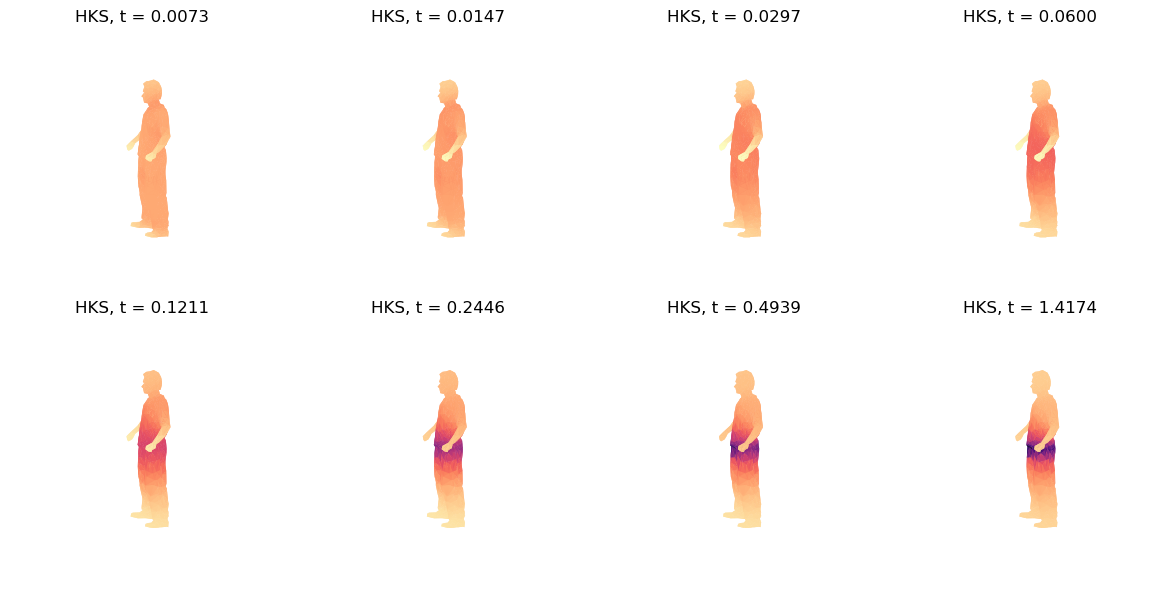

In [8]:
plotting.plot_hks(d["V"].numpy(), d["Fc"].numpy(), d["hks"], t, filename=ASSETS / "hks.png")

## Model
Loads `model.pt` if it exists (from `python python_scripts/train.py`), otherwise trains here and saves it.

In [9]:
model = MiniDiffusionNet(len(t), NUM_CLASSES).to(device)

if MODEL_PATH.exists():
    ckpt = torch.load(MODEL_PATH, map_location=device)
    model.load_state_dict(ckpt["model"])
    history = ckpt["history"]
    print(f"loaded {MODEL_PATH}")
else:
    history = train(model, train_dev, test_dev, epochs=100)
    torch.save({"model": model.state_dict(), "history": dict(history)}, MODEL_PATH)

loaded /home/filosofem/HumanBodySegmentation/model.pt


### Training curves

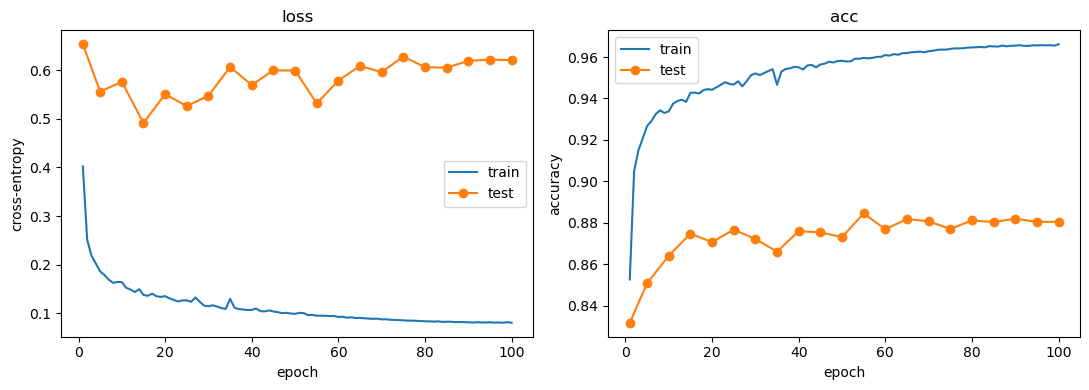

In [10]:
plotting.plot_history(history, filename=ASSETS / "history.png")

## Predictions
Ground truth, prediction, and errors (red) for the first test meshes.

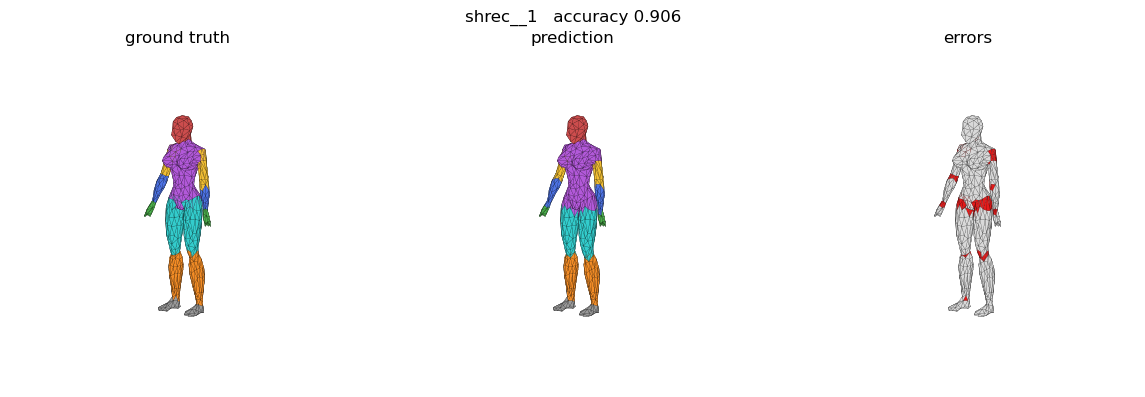

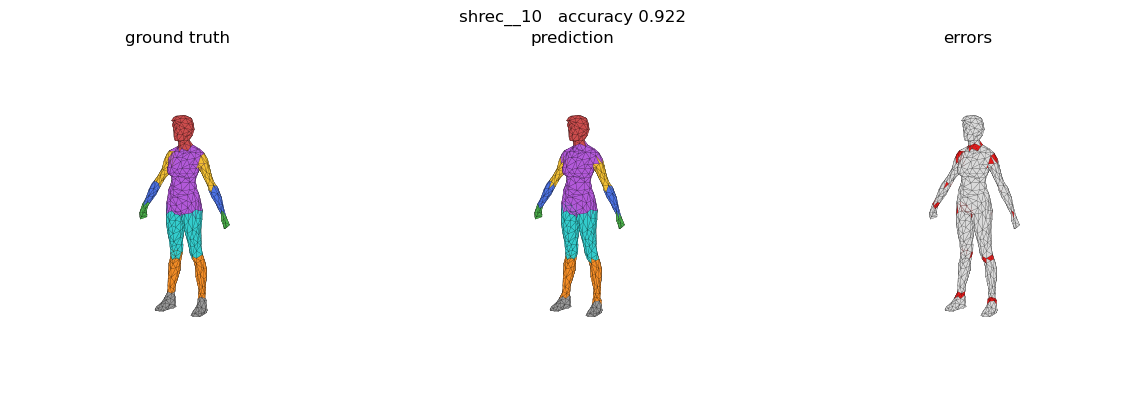

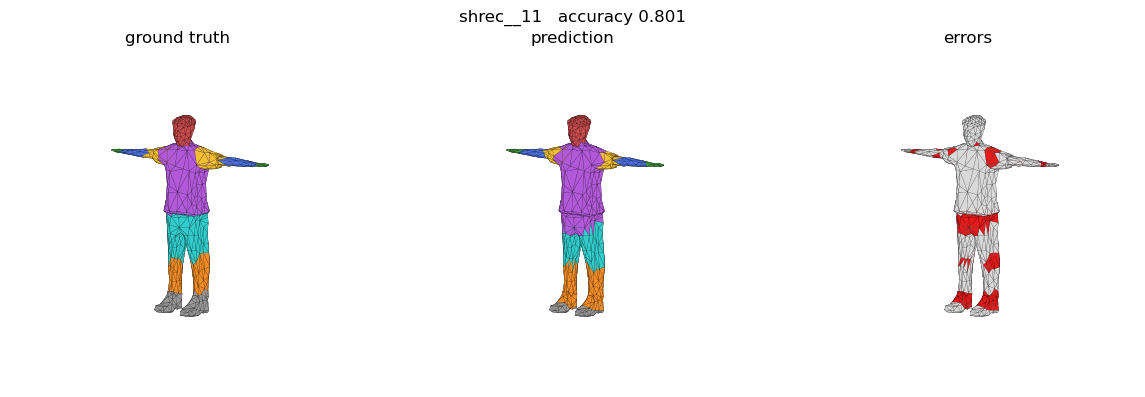

In [11]:
plotting.plot_predictions(model, test_data, test_dev, n=3)

## Confusion matrix and IoU
Row-normalized and area-weighted: the diagonal is the recall of each class.

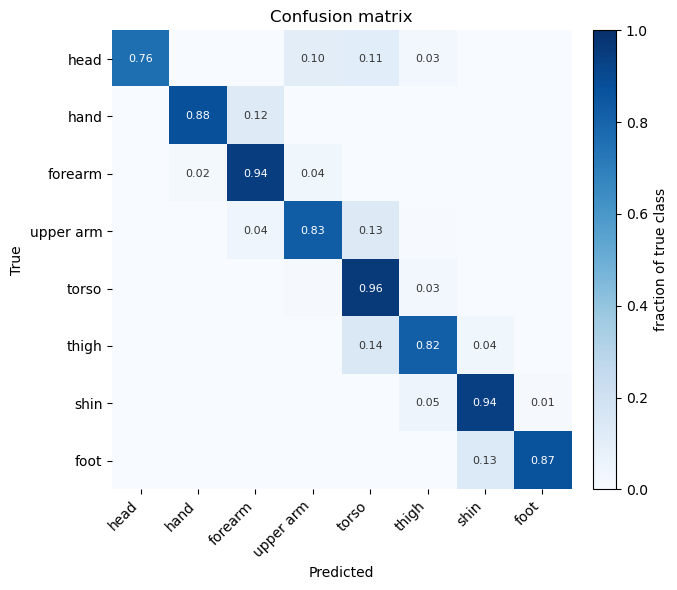

head       IoU 0.758
hand       IoU 0.847
forearm    IoU 0.840
upper arm  IoU 0.696
torso      IoU 0.823
thigh      IoU 0.757
shin       IoU 0.825
foot       IoU 0.848
mIoU 0.799


In [12]:
cm = confusion_matrix(model, test_data, test_dev)
plotting.plot_confusion_matrix(cm)

iou = iou_from_confusion(cm)
for name, v in zip(CLASS_NAMES, iou):
    print(f"{name:10s} IoU {v:.3f}")
print(f"mIoU {iou.mean():.3f}")